# Freight Rate Prediction

Predict freight rates with CatBoost regression using a date-based validation split.

## 1. Imports and data

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path("/home/ayyan-ahmed/Downloads/freight-rate-prediction/data")
OUTPUT_DIR = Path("/home/ayyan-ahmed/Downloads/freight-rate-prediction/output")
OUTPUT_DIR.mkdir(exist_ok=True)

train_df = pd.read_csv(DATA_DIR / "train-test.csv")
validation_df = pd.read_csv(DATA_DIR / "validation.csv")
december_df = pd.read_csv(DATA_DIR / "december-chart-inputs.csv")

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("December:", december_df.shape)
train_df.head()

Training: (48000, 14)
Validation: (12000, 13)
December: (31, 7)


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


## 2. Quick data checks

In [5]:
display(train_df.isna().sum().sort_values(ascending=False).head(10))
display(train_df["equipment"].value_counts())
display(train_df["posted_rate"].describe())

train_df["date"] = pd.to_datetime(train_df["date"])
validation_df["date"] = pd.to_datetime(validation_df["date"])
december_df["date"] = pd.to_datetime(december_df["date"])

market_index    374
weight          300
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
dtype: int64

equipment
Dry Van    27202
Reefer     12045
Flatbed     8753
Name: count, dtype: int64

count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64

## 3. Feature preparation

The ID is excluded. Date is converted to calendar features, and negative weights are treated as missing.

In [6]:
def prepare_features(df):
    data = df.copy()
    data = data.drop(columns=["load_id"], errors="ignore")
    data["date"] = pd.to_datetime(data["date"])
    data["month"] = data["date"].dt.month
    data["day"] = data["date"].dt.day
    data["dayofweek"] = data["date"].dt.dayofweek
    data["dayofyear"] = data["date"].dt.dayofyear
    data = data.drop(columns=["date"])

    if "weight" in data.columns:
        data.loc[data["weight"] < 0, "weight"] = np.nan

    cat_cols = [c for c in ["pickup", "delivery", "equipment"] if c in data.columns]
    for col in cat_cols:
        data[col] = data[col].fillna("Unknown").astype(str)
    return data, cat_cols

## 4. Time-based split

In [7]:
X = train_df.drop(columns=["posted_rate"])
y = train_df["posted_rate"]

train_mask = X["date"] < "2025-10-01"
valid_mask = X["date"] >= "2025-10-01"

X_train = X.loc[train_mask].copy()
X_valid = X.loc[valid_mask].copy()
y_train = y.loc[train_mask].copy()
y_valid = y.loc[valid_mask].copy()

X_train_ready, cat_cols = prepare_features(X_train)
X_valid_ready, _ = prepare_features(X_valid)

print("Training rows:", len(X_train_ready))
print("Validation rows:", len(X_valid_ready))

Training rows: 43147
Validation rows: 4853


## 5. Train and evaluate

In [8]:
model_log = CatBoostRegressor(
    iterations=1200, depth=8, learning_rate=0.03,
    loss_function="RMSE", random_seed=42, verbose=200
)
model_log.fit(
    X_train_ready, np.log1p(y_train),
    cat_features=cat_cols,
    eval_set=(X_valid_ready, np.log1p(y_valid)),
    early_stopping_rounds=100
)

valid_pred = np.expm1(model_log.predict(X_valid_ready)).clip(min=0.01)
metrics = pd.Series({
    "MAE": mean_absolute_error(y_valid, valid_pred),
    "RMSE": np.sqrt(mean_squared_error(y_valid, valid_pred)),
    "R2": r2_score(y_valid, valid_pred)
}, name="Validation score")
metrics

0:	learn: 0.6474290	test: 0.6640852	best: 0.6640852 (0)	total: 127ms	remaining: 2m 31s
200:	learn: 0.1509008	test: 0.1718180	best: 0.1718180 (200)	total: 10.2s	remaining: 50.7s
400:	learn: 0.1489652	test: 0.1711700	best: 0.1711464 (393)	total: 17.4s	remaining: 34.6s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.1711464369
bestIteration = 393

Shrink model to first 394 iterations.


MAE     108.206577
RMSE    647.710676
R2        0.820444
Name: Validation score, dtype: float64

## 6. Feature importance

distance        93.642160
equipment        2.595981
weight           0.756410
market_index     0.508777
dayofyear        0.427259
pickup_lat       0.311288
delivery_lat     0.300442
delivery_lon     0.282767
quote_signal     0.261602
month            0.221073
dtype: float64

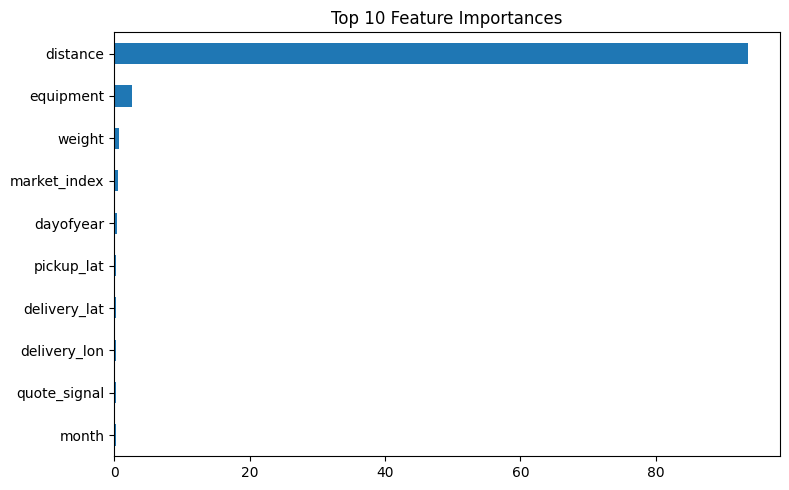

In [9]:
importance = pd.Series(
    model_log.get_feature_importance(), index=X_train_ready.columns
).sort_values(ascending=False)

display(importance.head(10))
importance.head(10).sort_values().plot(
    kind="barh", figsize=(8, 5), title="Top 10 Feature Importances"
)
plt.tight_layout()
plt.show()

## 7. Validation predictions

In [10]:
X_validation_ready, _ = prepare_features(validation_df)
validation_pred = np.expm1(model_log.predict(X_validation_ready)).clip(min=0.01)

validation_predictions = pd.DataFrame({
    "load_id": validation_df["load_id"],
    "predicted_rate": validation_pred
})
validation_predictions.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)

print("Saved:", OUTPUT_DIR / "validation_predictions.csv")
display(validation_predictions.head())
print("Rows:", len(validation_predictions))
print("Missing predictions:", validation_predictions["predicted_rate"].isna().sum())

Saved: /home/ayyan-ahmed/Downloads/freight-rate-prediction/output/validation_predictions.csv


,load_id,predicted_rate
0,TE-000001,874.706765
1,TE-000002,4870.303787
2,TE-000003,5041.908516
3,TE-000004,3984.631657
4,TE-000005,1808.720133


Rows: 12000
Missing predictions: 0


## 8. December predictions

The December file has fewer input columns, so this model uses only the shared features.

In [11]:
dec_features = ["pickup", "delivery", "distance", "equipment", "weight", "date"]
X_dec_train, dec_cat_cols = prepare_features(train_df[dec_features])
X_december, _ = prepare_features(december_df[dec_features])

dec_model = CatBoostRegressor(
    iterations=1200, depth=8, learning_rate=0.03,
    loss_function="RMSE", random_seed=42, verbose=200
)
dec_model.fit(
    X_dec_train, np.log1p(train_df["posted_rate"]),
    cat_features=dec_cat_cols
)

december_output = december_df[dec_features].copy()
december_output["date"] = december_output["date"].dt.strftime("%Y-%m-%d")
december_output["predicted_rate"] = np.expm1(
    dec_model.predict(X_december)
).clip(min=0.01)

december_output.to_csv(OUTPUT_DIR / "december_predictions.csv", index=False)
print("Saved:", OUTPUT_DIR / "december_predictions.csv")
display(december_output.head())

0:	learn: 0.6488629	total: 62.7ms	remaining: 1m 15s
200:	learn: 0.1548959	total: 9.28s	remaining: 46.1s
400:	learn: 0.1526306	total: 18.3s	remaining: 36.5s
600:	learn: 0.1512266	total: 26.8s	remaining: 26.7s
800:	learn: 0.1500303	total: 34.6s	remaining: 17.2s
1000:	learn: 0.1486317	total: 42.7s	remaining: 8.48s
1199:	learn: 0.1472487	total: 50.6s	remaining: 0us
Saved: /home/ayyan-ahmed/Downloads/freight-rate-prediction/output/december_predictions.csv


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,827.673361
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,839.234308
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,863.446596
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,862.772184
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,858.456408


## 9. Final checks

In [12]:
assert len(validation_predictions) == len(validation_df)
assert validation_predictions["load_id"].equals(validation_df["load_id"])
assert np.isfinite(validation_predictions["predicted_rate"]).all()
assert (validation_predictions["predicted_rate"] > 0).all()

assert len(december_output) == 31
assert december_output["date"].nunique() == 31
assert np.isfinite(december_output["predicted_rate"]).all()
assert (december_output["predicted_rate"] > 0).all()

print("All output checks passed.")

All output checks passed.
